# From a simulation snapshot to the fields of the optical depth

This notebook follows a hydrodynamical snapshot step by step, up to the fields and field samplers that SkewerJAX's optical-depth integral takes: gas cells → per-cell physics → the cells near a set of skewers → their pieces along every skewer → `Fields` and line elements.

Everything is SkewerJAX's default, which is also its most accurate mode. The optical depth itself is the subject of the companion notebook `6_optical_depth_from_simulations.ipynb`.

**Data.** TNG50-4, snapshot 025 (z = 3.008): a 35 cMpc/h periodic box, 19.3 million Voronoi gas cells in 11 HDF5 files, read-only from `/home/STORAGE/TNG50-4`.

**Order.** H I (Lyα) first, through every step; §7 shows what changes for a metal ion, Si III. §8 repeats the whole extraction in the format of the toy-model notebook `3_fields.ipynb`.

**Runtime.** About 2 min on a CPU (one full snapshot file is read in §3, all 19.3 million cell positions in §4, and §8 extracts four bundles).

## 0. Setup

The package style (`matplotlib_tol_config`: the default SkewerJAX style with Paul Tol's colour-blind-safe palette) and the paths. `CACHE` stores SkewerJAX results in an HDF5 file (this notebook computes no τ, so it is not used here).

In [1]:
import os, sys, time, warnings
os.environ.setdefault("JAX_PLATFORMS", "cpu")             # float64 runs faster on this CPU than on a consumer GPU
import logging; logging.getLogger("jax._src.xla_bridge").setLevel(logging.CRITICAL)
from pathlib import Path
import numpy as np, jax, jax.numpy as jnp
jax.config.update("jax_enable_x64", True)
import matplotlib as mpl
import matplotlib.pyplot as plt
from skewerjax.config.setup_matplotlib import (matplotlib_tol_config, TOL_BRIGHT as TOL, ENTITY_COLORS as EC, MODE_STYLES as MS,
                                               tol_cmap, add_panel_letters, residual_band)
font, rcnew = matplotlib_tol_config()                         # the package style with Paul Tol's colour-blind-safe palette
plt.rc("font", **font); plt.rcParams.update(rcnew)

# ------------------------------------------------------------------ configuration (edit here)
REPO = Path("/home/dlopez/Documentos/0.profesional/Postdoc/USP/Projects/SkewerJAX")
DATA = REPO / "claude_agents/tmp_files/20261021_1335"        # caches and fake_spectra reference data (to be moved: see the notebook header)
SNAP_BASE, SNAPNUM = "/home/STORAGE/TNG50-4", 25          # read-only
CACHE = DATA / "cache" / "sjx_cache.h5"                    # SkewerJAX tau results (None: no cache)
DS_KMS = 0.25                                                # spacing of the sampling points, in Hubble velocity [km/s]
RES = 1.0                                                    # spectral pixel [km/s]
T_START = time.perf_counter()
from skewerjax.simulations import snapshot_readers as sr, gas_physics as gp, cell_selection as sel
from skewerjax.simulations import simulation_skewers as ss
from skewerjax.fields import deposition as dep
from skewerjax.optical_depth import absorbers as ab_
from skewerjax.optical_depth.optical_depth import OpticalDepthCalculator
from skewerjax.skewers.skewers import SkewerBundle, path_geometry, axis_aligned_skewer_points
from skewerjax.constants.lines import LineBundle
from skewerjax.constants.physical_constants import phys
print("jax", jax.__version__, jax.devices()[0], "| x64", jax.config.jax_enable_x64)

RESULTS = []
def check(name, value, tol, section, kind="pass", detail=""):
    """kind="pass": PASS if value <= tol; "explained": EXPLAINED if value <= tol (a difference accounted
    for by its parts); "expect": PASS if value > tol (the test must detect something)."""
    ok = bool(value > tol) if kind == "expect" else bool(value <= tol)
    tag = {"pass": ("PASS", "FAIL"), "expect": ("PASS", "FAIL"), "explained": ("EXPLAINED", "UNEXPLAINED")}[kind][0 if ok else 1]
    RESULTS.append(dict(section=section, name=name, value=float(value), tol=tol, kind=kind, tag=tag, detail=detail))
    print(f"[{tag}] {section:5s} {name}: {value:.3e} ({'>' if kind == 'expect' else '<='} {tol:g}) {detail}")
def rel(a, b, mask=None):
    a, b = np.asarray(a, float), np.asarray(b, float)
    m = np.ones(a.shape, bool) if mask is None else np.asarray(mask, bool)
    return np.abs(a[m] - b[m]) / np.maximum(np.abs(b[m]), 1e-300)

jax 0.6.2 TFRT_CPU_0 | x64 True


## 1. What the optical depth needs

For transition j of species i, the optical depth along a path γ from the emitter to the observer is

$$\tau_{ij}(\Lambda)=\mathcal C_j\int_\gamma \frac{n_{i,\rm com}(\vec x)}{a(\vec x)^3}\,\phi_{ij}(\vec x,\Lambda)\,dl_{\rm phys},\qquad dl_{\rm phys}=a\,dl_{\rm com},\qquad \mathcal C_j=\frac{\pi e^2}{m_e c}\,f_j ,$$

with the Voigt profile, a Gaussian of Doppler parameter b convolved with the Lorentzian of the transition,

$$\phi_{ij}=V\!\Big(\frac{c}{\lambda_j}\Big[\frac{\lambda_j}{\lambda'}-1\Big];\ \sigma=\frac{b}{\sqrt2\,\lambda_j},\ \gamma=\frac{A_j}{4\pi}\Big),\qquad b=\sqrt{\frac{2k_BT}{m_i}},$$

evaluated at the rest-frame wavelength λ' that the gas at x sees when the observer measures the spectral coordinate Λ:

$$\frac{1}{\lambda'}=\frac{1}{\lambda_j}\,e^{-\Lambda/c}\,\frac{a_\dagger}{a(\vec x)}\sqrt{\frac{1-\beta}{1+\beta}},\qquad \beta=\frac{\vec v_{\rm pec}\cdot\hat d_\gamma}{c}.$$

Λ is a velocity-like coordinate, logarithmic in the observed wavelength, and a_† is a reference scale factor.

**The fields.** Per species, the integral needs only three fields along the path:
- the comoving number density n_com;
- the temperature T, which sets b;
- the peculiar velocity v_pec, projected on the photon direction.

Turbulent broadening and collisional damping are zero for a simulation.

**The Hubble flow is not a field.** It enters through the scale factor a(x) of every point. The cosmology fixes a(x) once the path is placed between the emitter and the observer, which is the subject of the companion notebook.

**Three discretisations.** Three grids are involved, and keeping them apart is the key to what follows:
- **(a) The simulation cells.** One value per Voronoi cell, i.e. a cell average. The cell is the region closer to its mesh-generating point than to any other.
- **(b) The sampling points of a `SkewerBundle`.** Point i stands for its **dual segment**, from the midpoint with its previous neighbour to the midpoint with its next one, of comoving length w_i: the **line element**.
- **(c) The spectral grid** of Λ on which τ is evaluated, chosen freely.

Discretised on (b), with p running over the pieces of cells inside segment i, each of exact length ℓ_p:

$$\tau(\Lambda)=\mathcal C\sum_i\int_{{\rm seg}\,i} \frac{n_{\rm com}}{a^{2}}\,\phi\,dl_{\rm com}\;\simeq\;\mathcal C\sum_i\sum_{p\in i}\frac{n_{{\rm com},p}\,\ell_p}{a_p^{2}}\,\phi_p(\Lambda),\qquad \sum_{p\in i}\ell_p=w_i .$$

A snapshot's density is piecewise constant, with jumps at the cell faces. So the fields at the points are not point values but **segment-integrated pieces**, each with its own n, T and v_pec. The line elements are part of the field definition: Σ_p n_p ℓ_p is the exact column of the segment for any spacing of the points. The figure shows the three grids on a toy two-dimensional mesh.

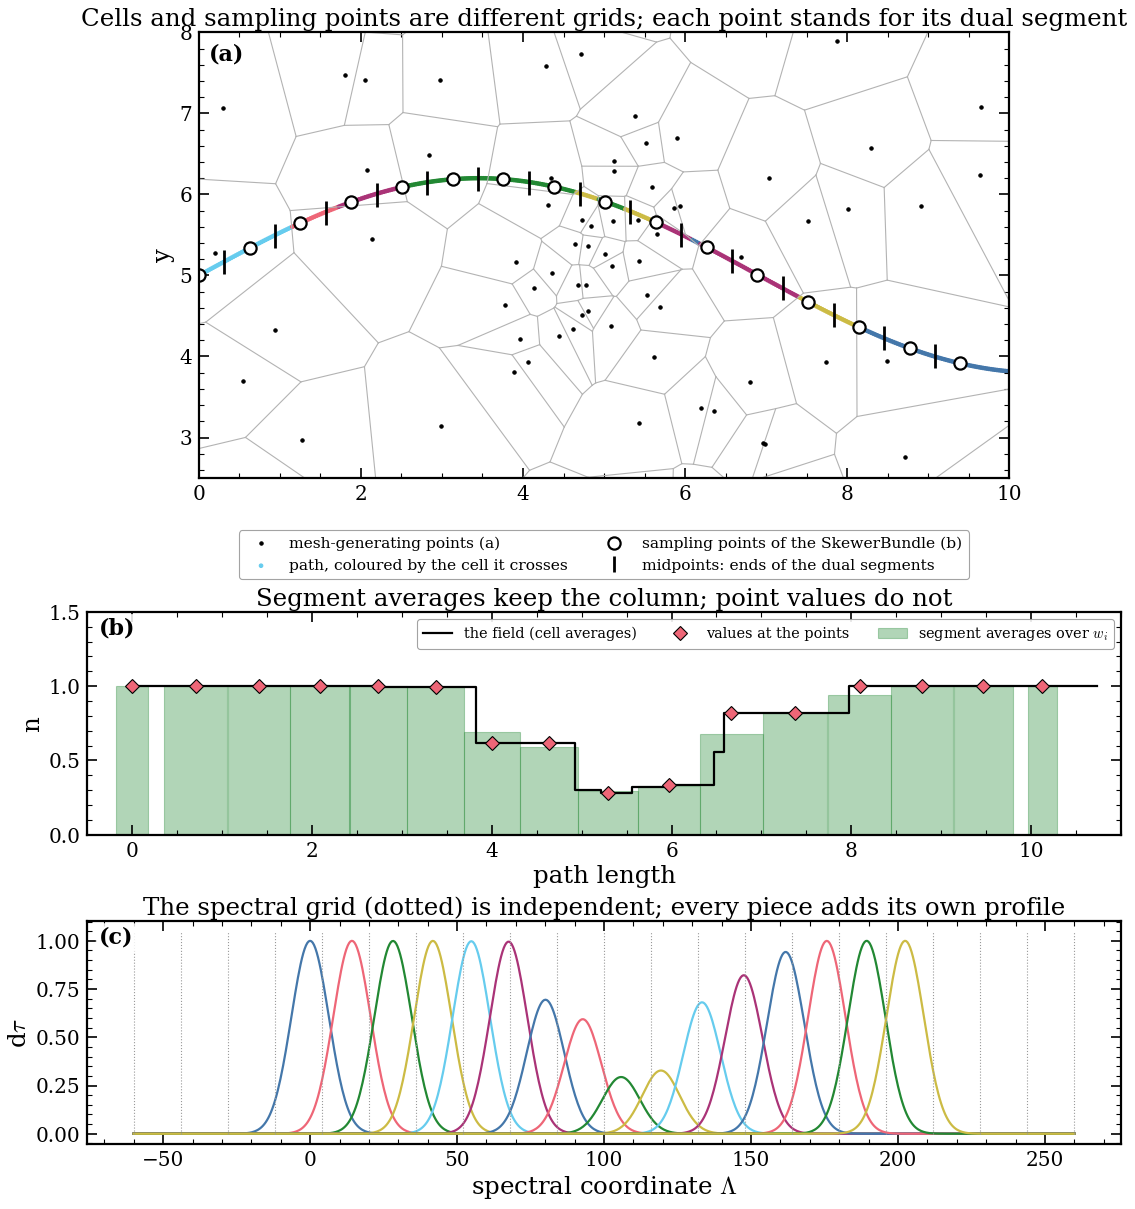

In [2]:
from scipy.spatial import Voronoi
rng = np.random.default_rng(3)
gen = np.vstack([rng.uniform(0, 10, (55, 2)), rng.normal([5, 5], 0.8, (35, 2))])        # a denser filament in the middle
tt = np.linspace(0, 10, 400); path = np.stack([tt, 5 + 1.2 * np.sin(tt / 2.2)], 1)
sp = path[::25]; mid = 0.5 * (sp[1:] + sp[:-1])
nearest = lambda P: np.argmin(((P[:, None, :] - gen[None]) ** 2).sum(-1), axis=1)
dens = 1 / (1 + 4 * np.exp(-((gen - 5) ** 2).sum(1)))
fig, axs = plt.subplots(3, 1, figsize=(14, 15), gridspec_kw={"height_ratios": [3, 1.5, 1.5]}, layout="constrained")
vor = Voronoi(np.vstack([gen, [[-50, -50], [-50, 60], [60, -50], [60, 60]]]))
for r in vor.ridge_vertices:
    if -1 not in r:
        axs[0].plot(*vor.vertices[r].T, color="0.7", lw=1.0)
axs[0].plot(*gen.T, "k.", ms=6, label="mesh-generating points (a)")
lab = nearest(path)
cyc = np.array([TOL["blue"], TOL["red"], TOL["green"], TOL["yellow"], TOL["cyan"], TOL["purple"]])
axs[0].scatter(*path.T, c=cyc[lab % len(cyc)], s=10, label="path, coloured by the cell it crosses")
axs[0].plot(*sp.T, "o", mfc="w", mec="k", mew=2, ms=11, label="sampling points of the SkewerBundle (b)")
for m in mid:
    axs[0].plot(*m, "|", color="k", ms=22, mew=2.5)
axs[0].plot([], [], "|", color="k", ms=14, mew=2.5, label="midpoints: ends of the dual segments")
axs[0].set(xlim=(0, 10), ylim=(2.5, 8.0), aspect="equal", ylabel="y")
axs[0].set_title("Cells and sampling points are different grids; each point stands for its dual segment")
axs[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncols=2, fontsize=14)
s_path = np.concatenate([[0], np.cumsum(np.linalg.norm(np.diff(path, axis=0), axis=1))])
n_path = dens[lab]; s_sp = s_path[::25]
w = np.asarray(path_geometry(jnp.asarray(np.c_[sp, np.zeros(len(sp))]))["line_elements"])
edges = np.concatenate([[0], 0.5 * (s_sp[1:] + s_sp[:-1]), [s_path[-1]]])
seg_mean = np.array([n_path[(s_path >= edges[i]) & (s_path < edges[i + 1])].mean() for i in range(len(sp))])
axs[1].bar(s_sp, seg_mean, width=w, alpha=0.35, color=EC["density"], edgecolor=EC["density"], label=r"segment averages over $w_i$")
axs[1].step(s_path, n_path, where="post", color="k", lw=2, label="the field (cell averages)")
axs[1].plot(s_sp, dens[nearest(sp)], "D", color=TOL["red"], ms=9, mec="k", label="values at the points")
axs[1].set(ylabel="n", xlabel="path length", ylim=(0, 1.5), xlim=(-0.5, 11))
axs[1].set_title("Segment averages keep the column; point values do not")
axs[1].legend(loc="upper right", ncols=3, fontsize=13)
vv = np.linspace(-60, 260, 700)
for i, (s0, nn) in enumerate(zip(s_sp, seg_mean)):
    axs[2].plot(vv, nn * np.exp(-((vv - 20 * s0) / 9) ** 2), lw=2, color=cyc[i % len(cyc)])
axs[2].vlines(np.arange(-60, 261, 16), 0, 1.05, color="0.6", lw=1, ls=":")
axs[2].set(xlabel=r"spectral coordinate $\Lambda$", ylabel=r"d$\tau$")
axs[2].set_title("The spectral grid (dotted) is independent; every piece adds its own profile")
add_panel_letters(axs)
plt.show()

*Figure — the three discretisations.*
- **Top:** Voronoi cells (a), a curved path crossing them, and the sampling points (b) with the boundaries of their dual segments.
- **Middle:** along the path the field is piecewise constant (black line). The value at a point (red diamonds) is whichever cell the point happens to fall in; the segment average (green bars) carries the segment's exact column.
- **Bottom:** the spectral grid (c) is independent of (b). Each piece's absorption is a profile centred where its a(x) and v_pec place it.

The rest of the notebook builds exactly this on the real snapshot.

## 2. Reading the snapshot (layers 1 and 2)

The extraction is split into layers. Each layer has one job and a small interface, so a new simulation format needs only a new reader:

| layer | module | job |
|---|---|---|
| 1 reader | `simulations/snapshot_readers.py` (`ArepoHDF5Reader`) | file layout, header, units; streams the gas in blocks |
| 2 container | `simulations/gas_cells.py` (`GasCells`) | positions [cMpc], volumes, fields in physical units (a JAX pytree) |
| 3 physics | `simulations/gas_physics.py` | n_H, T, x_HI, metal ion fractions, b |
| 4 selection | `simulations/cell_selection.py` | the cells that can touch the skewers |
| 5 deposition | `fields/deposition.py` | each cell's piece of each dual segment |
| 6 fields | `optical_depth/absorbers.py` | pieces → `SkewerBundle` + `Fields` + line elements |
| all | `simulations/simulation_skewers.py` (`SimulationSkewers`) | runs layers 1–6 for a set of skewers |

**The datasets and their units.** The reader converts code units with the attributes stored with each dataset (`a_scaling`, `h_scaling`, `to_cgs`):
- **`Coordinates`** [ckpc/h]: the **mesh-generating point** of each Voronoi cell, i.e. the point whose cell it is (not its centre of mass). The cells are the Voronoi tessellation of these points, so the nearest generating point of any position identifies the cell that contains it (§5).
- **`Velocities`** [km √a /s]: × √a gives the physical peculiar velocity [km/s].
- **`Density`**: comoving mass per comoving volume, so ρ_phys = ρ (UnitMass/UnitLength³) h²/a³. The volume of a cell is `Masses`/`Density`.
- **`InternalEnergy`** u [(km/s)²], **`ElectronAbundance`** n_e/n_H, **`NeutralHydrogenAbundance`** n_HI/n_H, **`GFM_Metals`** (mass fractions of H, He, C, N, O, Ne, Mg, Si, Fe), **`StarFormationRate`**.

In [3]:
rd = sr.ArepoHDF5Reader(SNAP_BASE, SNAPNUM)
H = rd.header; L = H.box_cMpc
print(f"{len(rd.files)} files, {H.n_gas:,} gas cells | z = {H.redshift:.6f}, a = {H.a:.8f}, h = {H.h}, box = {H.box_code} ckpc/h = {L:.4f} cMpc")
print(f"Omega_m = {H.omega_m}, Omega_L = {H.omega_l}, Omega_b = {H.omega_b} | a H(z) = {H.velfac_kms_per_cMpc:.5f} km/s per cMpc: "
      f"the box is {H.vmax_kms:.1f} km/s of Hubble flow")
print(f"mean cell size (L^3/N)^(1/3) = {L / H.n_gas ** (1 / 3) * 1e3:.0f} ckpc = {L / H.n_gas ** (1 / 3) * H.velfac_kms_per_cMpc:.1f} km/s of Hubble flow\n")
print(f"{'dataset':26s} a_scaling h_scaling to_cgs")
for k in ("Coordinates", "Masses", "Density", "Velocities", "InternalEnergy", "ElectronAbundance", "NeutralHydrogenAbundance",
          "GFM_Metals", "StarFormationRate"):
    at = rd.dataset_attrs[k]
    print(f"{k:26s} {str(at.get('a_scaling', '-')):9s} {str(at.get('h_scaling', '-')):9s} {at.get('to_cgs', '-')}")
blk = rd.read_rows(0, ["Coordinates", "CenterOfMass", "Masses", "Density"], start=0, stop=200000)
off = blk["CenterOfMass"] - blk["Coordinates"]; off -= H.box_code * np.round(off / H.box_code)
hh = np.cbrt(blk["Masses"] / blk["Density"])
print(f"\n|CenterOfMass - Coordinates| / V^(1/3) (200,000 cells): median {np.median(np.linalg.norm(off, axis=1) / hh):.3f} "
      f"-> the generating points are close to, but not at, the mass centroids")

11 files, 19,250,411 gas cells | z = 3.008131, a = 0.24949284, h = 0.6774, box = 35000.0 ckpc/h = 51.6681 cMpc
Omega_m = 0.3089, Omega_L = 0.6911, Omega_b = 0.0486 | a H(z) = 76.67289 km/s per cMpc: the box is 3961.5 km/s of Hubble flow
mean cell size (L^3/N)^(1/3) = 193 ckpc = 14.8 km/s of Hubble flow

dataset                    a_scaling h_scaling to_cgs
Coordinates                1.0       -1.0      3.085678e+21
Masses                     0.0       -1.0      1.989e+43
Density                    -3.0      2.0       6.769911178294544e-22
Velocities                 0.5       0.0       100000.0
InternalEnergy             0.0       0.0       10000000000.0
ElectronAbundance          0.0       0.0       0.0
NeutralHydrogenAbundance   0.0       0.0       0.0
GFM_Metals                 0.0       0.0       0.0
StarFormationRate          0.0       0.0       6.302760666210359e+25

|CenterOfMass - Coordinates| / V^(1/3) (200,000 cells): median 0.174 -> the generating points are close to, but not

**Layer 2, `GasCells`.** The reader returns the cells as a `GasCells` container: positions in comoving Mpc (no h) wrapped into [0, L), volumes, and a dictionary of fields in physical units. It is a JAX pytree, so everything downstream can be jitted or differentiated. The size of a cell is V^(1/3).

In [4]:
raw = rd.read_rows(0, ["Coordinates", "Masses", "Density", "InternalEnergy", "ElectronAbundance", "NeutralHydrogenAbundance",
                       "GFM_Metals", "StarFormationRate", "Velocities"])
C0 = rd.to_gas_cells(raw)
print(f"GasCells of file 0: {len(C0):,} cells, {C0.nbytes() / 1e6:.0f} MB | box {C0.box:.4f} cMpc, a = {C0.a:.6f}")
for k, v in C0.fields.items():
    print(f"  {k:12s} {str(np.shape(v)):14s} median {np.median(np.asarray(v), axis=0) if np.ndim(v) == 1 else np.median(np.asarray(v), axis=0)[:3]}")
print(f"  cell size V^(1/3): median {np.median(np.asarray(C0.size_cMpc)) * 1e3:.0f} ckpc, range {np.min(C0.size_cMpc) * 1e3:.2f}-{np.max(C0.size_cMpc) * 1e3:.0f} ckpc")

GasCells of file 0: 1,786,430 cells, 300 MB | box 51.6681 cMpc, a = 0.249493
  rho          (1786430,)     median 4.934459344509745e-27
  u            (1786430,)     median 8211582336425.781
  n_e          (1786430,)     median 1.1386554837226868
  x_HI_stored  (1786430,)     median 0.00026324721693526953
  metals       (1786430, 9)   median [7.59925961e-01 2.40038872e-01 1.69260284e-06]
  sfr          (1786430,)     median 0.0
  velocity     (1786430, 3)   median [-1.76470991 -2.36081562  3.50686508]
  cell size V^(1/3): median 34 ckpc, range 0.20-269 ckpc


## 3. Per-cell physics (layer 3): n, T, x_HI, v_pec, b

For each cell (`gas_physics.ion_properties`):

- **Hydrogen density.** With X_H the hydrogen mass fraction and A_H = 1.00794 its atomic weight in atomic mass units m_u,
$$n_{\rm H}=\frac{\rho\,X_{\rm H}}{A_{\rm H}\,m_u}.$$
The mass of an atom is A m_u, by definition of the atomic weight.
- **Temperature.** From the specific internal energy u, with γ = 5/3 and the mean molecular weight set by the stored electron abundance (X = 0.76):
$$T=(\gamma-1)\,\mu\,\frac{m_p\,u}{k_B},\qquad \mu=\frac{4}{1+3X+4X\,n_e/n_{\rm H}}.$$
- **Neutral fraction.** The simulation stores x_HI = n_HI/n_H, computed while it ran: ionisation equilibrium with its UV background, the local radiation of active black holes and self-shielding of dense gas. Without self-shielding and AGN radiation the equilibrium is
$$x_{\rm HI}=\frac{\alpha(T)}{\alpha(T)+\Gamma_e(T)+\Gamma_{\rm HI}/n_e},$$
with α the recombination and Γ_e the collisional ionisation coefficient, Γ_HI the photoionisation rate of the background and n_e the electron density. SkewerJAX keeps the stored value, which is consistent with the simulation's own heating and cooling. The exception is **star-forming cells**: they sit on an effective equation of state whose temperature is not physical, so their x_HI is recomputed as the cold, self-shielded phase at T = 10⁴ K (`x_HI_model="stored_sf"`).
- **Ion density and velocity:** n_HI = x_HI n_H [physical cm⁻³ at the snapshot epoch], and v_pec = √a × `Velocities`.
- **Doppler parameter:** b = √(2 k_B T / (A m_u)), for H I b = 12.85 km/s × (T/10⁴ K)^(1/2).

Below, the equilibrium formula is checked against the stored x_HI over one full file (1.75 million cells), in diffuse gas where neither shielding nor AGN radiation acts.

Gamma_HI(z) of the simulation's UV background: 5.476e-13 s^-1 | star-forming cells in this file: 119,747 (6.70%)
[PASS] 3     stored x_HI == ionisation equilibrium (diffuse gas, n_H < 1e-4 cm^-3): median |ratio - 1|: 9.291e-04 (<= 0.002) (41,291 cells)
[PASS] 3     default x_HI = stored outside star-forming cells: 0.000e+00 (<= 0) 


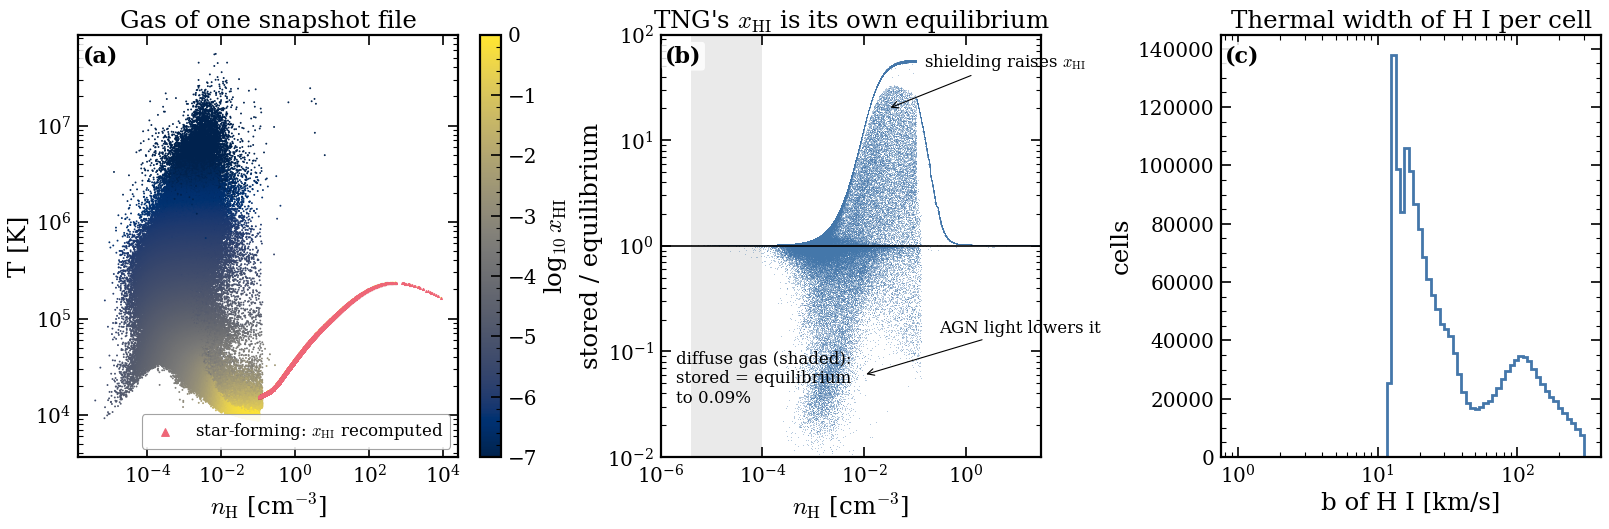

In [5]:
P0 = gp.ion_properties(C0, gp.HI)
nH0, T0_, x0 = (np.asarray(P0[k]) for k in ("n_H", "T", "ion_fraction"))
sf0 = np.asarray(C0.fields["sfr"]) > 0
nH_arepo = np.asarray(C0.fields["rho"]) * np.asarray(C0.fields["metals"])[:, 0] / phys.mp        # the simulation's own n_H = X rho / m_p
G = gp.treecool_rates(H.redshift, gp.default_treecool_path())["Gamma_HI"]
x_eq = np.asarray(gp.arepo_equilibrium_neutral_fraction(nH_arepo, T0_, C0.fields["n_e"], G))
diffuse = ~sf0 & (nH_arepo < 1e-4)
print(f"Gamma_HI(z) of the simulation's UV background: {G:.3e} s^-1 | star-forming cells in this file: {sf0.sum():,} ({sf0.mean():.2%})")
check("stored x_HI == ionisation equilibrium (diffuse gas, n_H < 1e-4 cm^-3): median |ratio - 1|",
      np.median(np.abs(np.asarray(C0.fields["x_HI_stored"])[diffuse] / x_eq[diffuse] - 1)), 2e-3, "3", detail=f"({diffuse.sum():,} cells)")
check("default x_HI = stored outside star-forming cells", np.abs(x0[~sf0] - np.asarray(C0.fields["x_HI_stored"])[~sf0]).max(), 0, "3")
fig, axs = plt.subplots(1, 3, figsize=(20, 6.5), layout="constrained")
ii = np.arange(0, len(C0), 7)
sc = axs[0].scatter(nH0[ii], T0_[ii], c=np.log10(x0[ii]), s=0.5, cmap="cividis", vmin=-7, vmax=0, rasterized=True)
axs[0].scatter(nH0[sf0], T0_[sf0], s=3, color=TOL["red"], marker="^", label="star-forming: $x_{\\rm HI}$ recomputed")
axs[0].set(xscale="log", yscale="log", xlabel=r"$n_{\rm H}$ [cm$^{-3}$]", ylabel="T [K]", title="Gas of one snapshot file")
axs[0].legend(loc="lower right", markerscale=4)
fig.colorbar(sc, ax=axs[0], label=r"log$_{10}\,x_{\rm HI}$")
axs[1].loglog(nH_arepo[ii], (np.asarray(C0.fields["x_HI_stored"]) / x_eq)[ii], ",", color=EC["HI"], alpha=0.4, rasterized=True)
axs[1].axhline(1, color="k", lw=1.5)
axs[1].axvspan(nH_arepo.min(), 1e-4, color=TOL["grey"], alpha=0.3, lw=0)
axs[1].text(2e-6, 0.03, "diffuse gas (shaded):\nstored = equilibrium\nto 0.09%", fontsize=15, va="bottom")
axs[1].annotate("shielding raises $x_{\\rm HI}$", xy=(3e-2, 20), xytext=(1.5e-1, 50), fontsize=15, arrowprops=dict(arrowstyle="->"))
axs[1].annotate("AGN light lowers it", xy=(1e-2, 0.06), xytext=(0.3, 0.15), fontsize=15, arrowprops=dict(arrowstyle="->"))
axs[1].set(xlabel=r"$n_{\rm H}$ [cm$^{-3}$]", ylabel="stored / equilibrium", ylim=(1e-2, 1e2), xlim=(1e-6, 3e1),
           title="TNG's $x_{\\rm HI}$ is its own equilibrium")
axs[2].hist(np.asarray(gp.doppler_b_kms(T0_, 1.00794)), bins=np.geomspace(1, 300, 80), histtype="step", color=EC["HI"], lw=2.5)
axs[2].set(xscale="log", xlabel="b of H I [km/s]", ylabel="cells", title="Thermal width of H I per cell")
add_panel_letters(axs)
plt.show()

*Figure — left:* the temperature–density plane of one snapshot file, coloured by the neutral fraction; star-forming cells in red. *Middle:* the stored x_HI over the unshielded equilibrium. It is 1 in diffuse gas. It rises at high density, where the gas shields itself from the background, and it drops in the cells reached by AGN radiation. *Right:* the thermal width b of H I in every cell, from ≈12 km/s (T ≈ 10⁴ K, the coldest gas of this file) to ≈300 km/s in shocked haloes.

## 4. Skewers through the box, and the cells near them (layer 4)

**The sampling points (b).** A skewer is any polyline through the box, given as the points of a `SkewerBundle` (comoving Mpc, unwrapped along the path; the box is periodic, so the path may cross its faces). Here the skewers run along the box axes and are sampled every `DS_KMS` = 0.25 km/s of Hubble flow (Δs = 3.3 ckpc). The first and last points are the same place of the periodic box, so their two half-segments together cover it once.

`SimulationSkewers.axis_aligned(reader, cofm, axis, spacing)` builds the points and selects the cells:
- `"single"`: one skewer along z;
- `"nset"`: 16 skewers at random positions along x, y and z in turn.

**Selection.** A cell can contribute to a segment only if the segment's points lie in the cell, so the cell's generating point is within reach of a path point. A periodic k-d tree is built on the path points (minimum-image distances), and the snapshot is streamed block by block. A cell is kept if a path point lies within d ≤ 2.5 h + Δs/2, with h = V^(1/3). Memory is bounded by one block plus the tree, whatever the snapshot size.

In [6]:
SETS = dict(single=dict(axis=np.array([3], dtype=np.int32), cofm=np.array([[17500.25, 17500.75, 0.0]])),
            nset=dict(axis=np.tile(np.array([1, 2, 3], dtype=np.int32), 6)[:16], cofm=np.random.default_rng(2155).uniform(0.0, 35000.0, size=(16, 3))))
SK = {}
for name, cfg in SETS.items():
    SK[name] = ss.SimulationSkewers.axis_aligned(rd, cfg["cofm"], cfg["axis"], DS_KMS, name=name, cache=CACHE)
    S = SK[name]
    print(f"{name:6s}: {S.n_skewers:2d} skewers x {S.points.shape[1]} points | {len(S.cells):6d} cells selected in {S.selection_s:.1f} s "
          f"({S.cells.nbytes() / 1e6:.1f} MB)")
S = SK["single"]
check("line elements of a skewer sum to the box length", np.abs(S.line_elements.sum(-1) - L).max() / L, 1e-12, "4")

single:  1 skewers x 15847 points |   4583 cells selected in 3.6 s (0.8 MB)
nset  : 16 skewers x 15847 points |  71211 cells selected in 5.6 s (12.5 MB)
[PASS] 4     line elements of a skewer sum to the box length: 0.000e+00 (<= 1e-12) 


[PASS] 4     selection complete (single): the nearest generating point over all 19,250,411 cells is selected: 0.000e+00 (<= 0) (31,694 probes)
[PASS] 4     selection complete (nset): the nearest generating point over all 19,250,411 cells is selected: 0.000e+00 (<= 0) (507,104 probes)
brute-force check: 6 s


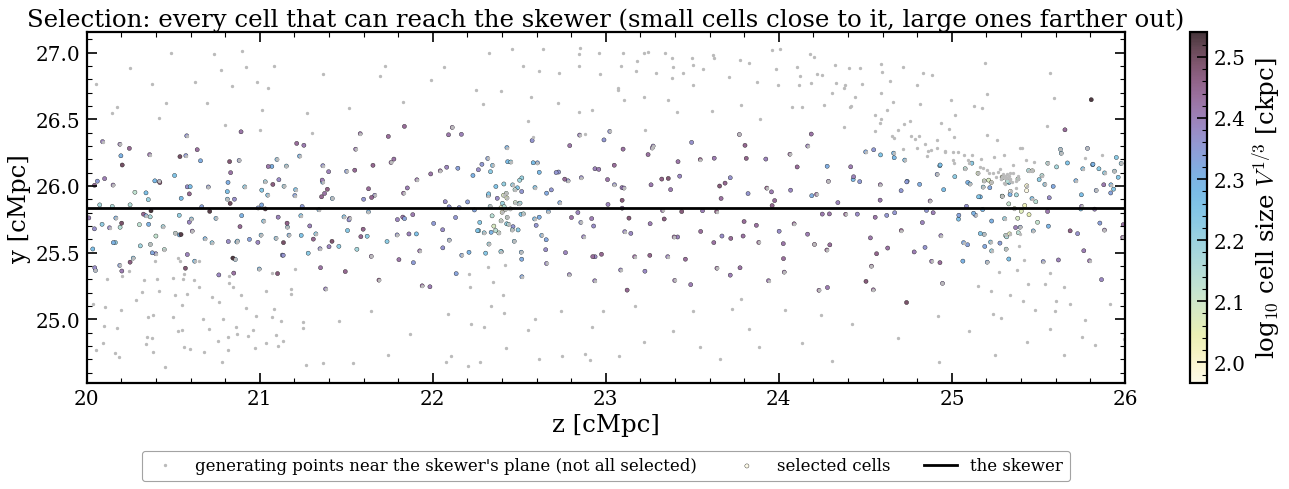

In [7]:
# Is the selection complete? The nearest generating point of every sampling point and segment end, searched over ALL cells,
# must be one of the selected cells.
from scipy.spatial import cKDTree
t = time.perf_counter()
allpos = np.concatenate([rd.positions_cMpc(b["Coordinates"]) for _, _, b in rd.iter_blocks(["Coordinates"])])
tree_all = cKDTree(allpos, boxsize=L)
for name in ("single", "nset"):
    S = SK[name]; g = path_geometry(jnp.asarray(S.points))
    probe = np.mod(np.concatenate([S.points.reshape(-1, 3), np.asarray(g["mid_hi"]).reshape(-1, 3)]), L)
    _, i_all = tree_all.query(probe)
    _, i_sel = cKDTree(np.asarray(S.cells.positions), boxsize=L).query(probe)
    miss = np.any(np.asarray(S.cells.positions)[i_sel] != allpos[i_all], axis=1)
    check(f"selection complete ({name}): the nearest generating point over all {len(allpos):,} cells is selected", float(miss.mean()), 0, "4",
          detail=f"({probe.shape[0]:,} probes)")
print(f"brute-force check: {time.perf_counter() - t:.0f} s")
S = SK["single"]; pos = np.asarray(S.cells.positions)
slab = np.abs((allpos[:, 0] - S.points[0, 0, 0] + L / 2) % L - L / 2) < 0.15
win = slab & (allpos[:, 2] > 20) & (allpos[:, 2] < 26) & (np.abs(allpos[:, 1] - S.points[0, 0, 1]) < 1.2)
sw = (np.abs(pos[:, 2] - 23) < 3) & (np.abs(pos[:, 1] - S.points[0, 0, 1]) < 1.2)
fig, ax = plt.subplots(figsize=(16, 6), layout="constrained")
ax.plot(allpos[win, 2], allpos[win, 1], ".", ms=4, color=TOL["grey"], label="generating points near the skewer's plane (not all selected)")
scs = ax.scatter(pos[sw, 2], pos[sw, 1], s=14, c=np.log10(np.asarray(S.cells.size_cMpc)[sw] * 1e3), cmap=tol_cmap("iridescent"),
                 edgecolor="k", linewidth=0.3, label="selected cells")
fig.colorbar(scs, ax=ax, label=r"log$_{10}$ cell size $V^{1/3}$ [ckpc]")
ax.axhline(S.points[0, 0, 1], color="k", lw=2.5, label="the skewer")
ax.set(xlim=(20, 26), xlabel="z [cMpc]", ylabel="y [cMpc]",
       title="Selection: every cell that can reach the skewer (small cells close to it, large ones farther out)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncols=3); plt.show()
del allpos, tree_all

## 5. Deposition: the pieces of every dual segment (layer 5)

For every sampling point, the deposition returns the pieces of gas on its dual segment: the cell, the exact length ℓ_p of the piece, and the offset of its centroid from the point (`deposition.voronoi_segments`, a `SegmentComponents`).

**The Voronoi geometry.** Along a straight half-segment A + t(B − A), t ∈ [0, 1], the squared distance to generating point g is

$$|A-g|^2+2t\,(A-g)\cdot(B-A)+t^2|B-A|^2 .$$

The last term is the same for every g, so "the nearest generating point" is the lower envelope of **straight lines** in t. Each change of cell is located exactly, at the crossing of two lines. The segment is first labelled at sub-points spaced finer than the smallest selected cell, then every change of label is refined to the exact crossing. Generating points are always taken at their minimum image relative to the point, so a path may cross the box faces any number of times.

**What a piece carries.** Its cell's n, T and v_pec (projected on the local tangent of the path), its length ℓ_p and its position s_p along the path. The column of a segment is exact:

$$N_i=a\sum_{p\in i} n_p\,\ell_p,\qquad \sum_{p\in i}\ell_p=w_i,\qquad N=\sum_i N_i=a\int n\,dl_{\rm com}.$$

single: Voronoi deposition   0.1 s | pieces per segment: mean 1.02, max 2 (sub-points per half-segment 8, sub-interval / smallest cell 0.00)
[PASS] 5     the pieces fill every dual segment exactly (single): 2.179e-12 (<= 1e-09) 
nset  : Voronoi deposition   0.9 s | pieces per segment: mean 1.02, max 3 (sub-points per half-segment 8, sub-interval / smallest cell 0.02)
[PASS] 5     the pieces fill every dual segment exactly (nset): 2.179e-12 (<= 1e-09) 


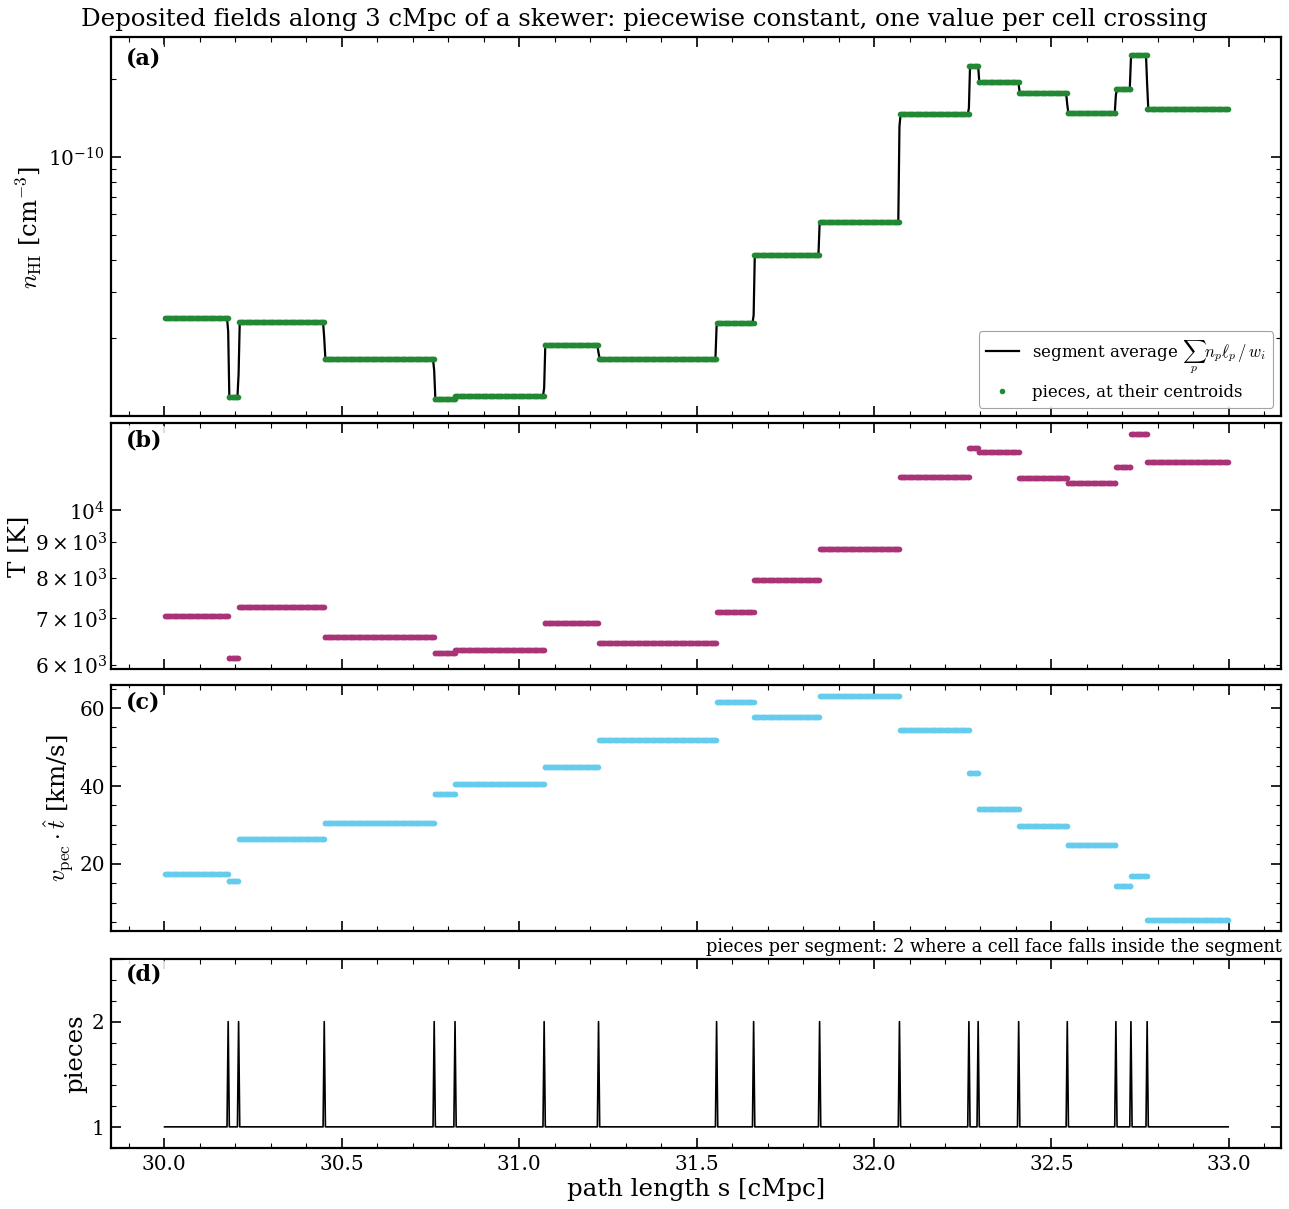

In [8]:
for name, S in SK.items():
    t = time.perf_counter(); seg = S.segments("voronoi"); dt = time.perf_counter() - t
    nc = seg.n_components
    print(f"{name:6s}: Voronoi deposition {dt:5.1f} s | pieces per segment: mean {nc.mean():.2f}, max {nc.max()} "
          f"(sub-points per half-segment {seg.diagnostics['n_sub']}, sub-interval / smallest cell {seg.diagnostics['sub_over_min_cell']:.2f})")
    check(f"the pieces fill every dual segment exactly ({name})", np.abs(seg.length.sum(-1) - S.line_elements).max() / S.line_elements.max(), 1e-9, "5")
S = SK["single"]; P = S.properties(gp.HI); seg = S.segments("voronoi")
segv = dep.segment_fields(seg, P["n_ion"], P["T"], np.zeros(seg.cell.shape))
s_pts = S.s[0]; w0 = S.line_elements[0]
A1 = S.absorbers(gp.HI)
win = (s_pts > 30.0) & (s_pts < 33.0)
live = (A1.n[0] > 0) & (A1.s[0] > 30) & (A1.s[0] < 33)
fig, axs = plt.subplots(4, 1, figsize=(16, 15), sharex=True, layout="constrained", gridspec_kw={"height_ratios": [2, 1.3, 1.3, 1]})
axs[0].semilogy(s_pts[win], (segv["column_length"][0] / w0)[win], color="k", lw=2, label=r"segment average $\sum_p n_p\ell_p\,/\,w_i$")
axs[0].semilogy(A1.s[0][live], A1.n[0][live], "o", ms=4, color=EC["density"], label="pieces, at their centroids")
axs[0].set(ylabel=r"$n_{\rm HI}$ [cm$^{-3}$]"); axs[0].legend(loc="lower right")
axs[1].semilogy(A1.s[0][live], A1.T[0][live], "o", ms=4, color=EC["temperature"]); axs[1].set(ylabel="T [K]")
axs[2].plot(A1.s[0][live], A1.v_los[0][live], "o", ms=4, color=EC["velocity"]); axs[2].set(ylabel=r"$v_{\rm pec}\cdot\hat t$ [km/s]")
axs[3].plot(s_pts[win], seg.n_components[0][win], color="k", lw=1.5); axs[3].set(ylabel="pieces", xlabel="path length s [cMpc]", yticks=[1, 2], ylim=(0.8, 2.6))
axs[3].set_title("pieces per segment: 2 where a cell face falls inside the segment", fontsize=16, loc="right")
fig.suptitle("Deposited fields along 3 cMpc of a skewer: piecewise constant, one value per cell crossing", fontsize=22)
add_panel_letters(axs)
plt.show()

*Figure — the deposited fields along 3 cMpc of the single skewer.* Each piece (dots, one per cell crossing inside each segment) has its own density, temperature and line-of-sight peculiar velocity. Together they are piecewise constant along the path, as the cells are. The segment average (black line) is n integrated over the segment, divided by w_i. Most segments hold one piece, and two where a cell face falls inside them (bottom).

**The column per position pixel, and the sampling.** Binned into equal position pixels, the pieces give the H I column along the skewer (`column_per_pixel`, exact: each piece is an interval). Because every segment carries its exact column, the total column does not depend on the spacing of the points: below, the 16 skewers are re-sampled from 0.25 to 64 km/s (the mean cell is ~15 km/s long), and N_HI is recomputed each time.

 spacing [km/s]  points/skewer   max |dN/N| over the 16 skewers
           0.25          15847                          0.0e+00
           1.00           3963                          4.4e-16
           4.00            991                          9.4e-06
          16.00            249                          9.4e-06
          64.00             63                          9.4e-06
[PASS] 5     the column is independent of the spacing of the points (0.25-64 km/s, 16 skewers): 9.395e-06 (<= 2e-05) 
[PASS] 5     column per pixel sums to the total column: 6.262e-14 (<= 1e-10) 
total N_HI per skewer [log10 cm^-2]: 15.83 15.66 15.68 16.13 16.60 15.97 15.48 15.93 19.41 15.80 15.88 16.55 16.16 15.43 17.03 15.62


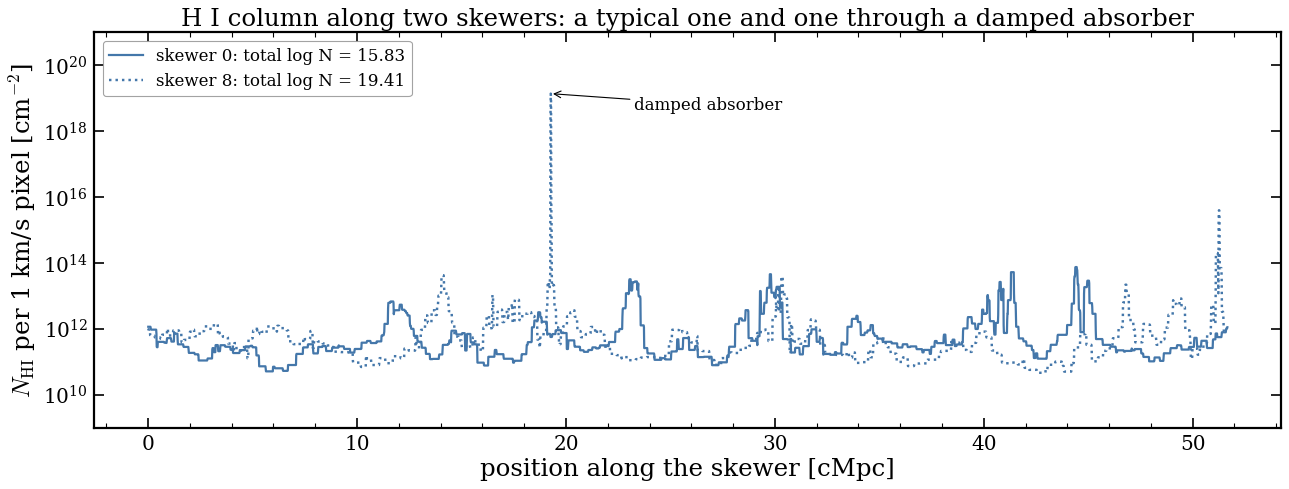

In [9]:
S = SK["nset"]; P = S.properties(gp.HI)
N_ref = S.segments("voronoi").column_lengths(P["n_ion"]).sum(-1)
print(f"{'spacing [km/s]':>15s} {'points/skewer':>14s} {'max |dN/N| over the 16 skewers':>32s}")
worst = 0.0
for ds in (0.25, 1.0, 4.0, 16.0, 64.0):
    pts = axis_aligned_skewer_points(SETS["nset"]["cofm"] * H.code_length_cMpc, SETS["nset"]["axis"], L, ds / H.velfac_kms_per_cMpc)
    seg_ds = dep.voronoi_segments(pts, S.cells.positions, L, gas_size=S.cells.size_cMpc)
    e = np.abs(seg_ds.column_lengths(P["n_ion"]).sum(-1) / N_ref - 1).max(); worst = max(worst, e)
    print(f"{ds:15.2f} {pts.shape[1]:14d} {e:32.1e}")
check("the column is independent of the spacing of the points (0.25-64 km/s, 16 skewers)", worst, 2e-5, "5")
Ncol = S.column_per_pixel(gp.HI)
check("column per pixel sums to the total column", np.abs(Ncol.sum(-1) / (N_ref * 3.085678e24 * H.a) - 1).max(), 1e-10, "5")
logN = np.log10(np.maximum(Ncol.sum(-1), 1))
print("total N_HI per skewer [log10 cm^-2]:", " ".join(f"{x:.2f}" for x in logN))
fig, ax = plt.subplots(figsize=(16, 6), layout="constrained")
xpix = (np.arange(Ncol.shape[1]) + 0.5) * L / Ncol.shape[1]
for k, sty in ((0, MS["default"]), (8, MS["alternative"])):
    ax.semilogy(xpix, np.maximum(Ncol[k], 1e6), color=EC["HI"], **sty, label=f"skewer {k}: total log N = {logN[k]:.2f}")
j8 = np.argmax(Ncol[8])
ax.annotate("damped absorber", xy=(xpix[j8], Ncol[8][j8]), xytext=(xpix[j8] + 4, Ncol[8][j8] / 3), fontsize=15, arrowprops=dict(arrowstyle="->"))
ax.set(xlabel="position along the skewer [cMpc]", ylabel=r"$N_{\rm HI}$ per 1 km/s pixel [cm$^{-2}$]", ylim=(1e9, 1e21),
       title="H I column along two skewers: a typical one and one through a damped absorber")
ax.legend(loc="upper left"); plt.show()

The total column is unchanged to ≤ 10⁻⁵ when the spacing grows 256-fold, even with segments four times longer than the mean cell. The residual comes from cells grazed over less than one sub-interval. The spacing therefore does not decide the column. It only decides *where* inside a segment each piece absorbs, which matters for the line shapes: that resolution criterion belongs to the optical depth and is the subject of the companion notebook.

## 6. The fields and field samplers that the optical depth takes (layer 6)

`SimulationSkewers.absorbers(ion)` flattens the pieces of all the segments of a skewer into one list, an `Absorbers` with arrays (N_sk, M):
- s, the path coordinate of the piece's centroid;
- n, the ion density [physical cm⁻³ at the snapshot epoch];
- ℓ, the length [cMpc];
- T [K];
- v_los, the peculiar velocity along the path [km/s].

They are turned into exactly what `OpticalDepthCalculator` takes by `absorbers.optical_depth_inputs`:

| input | what it holds |
|---|---|
| `skewer_bundle` | one point per piece, at its path coordinate, in rows of `chunk` points (fixed shapes, padded with n = 0); its scale factors are a(s) of the chosen frame; photons travel towards decreasing s |
| `fields` | `Fields({species: {...}})` whose samplers are `SampledField`s: they return the pieces' own T, v_pec and comoving density n_com = n a³, without interpolation; turbulence and collisional broadening are 0 |
| `line_elements` | the length ℓ_p of each piece: the weights of the quadrature, instead of the trapezoid weights of the points |

So the line elements are part of the field definition: a simulation's "field sampler" is the list of pieces with their lengths, and the integral becomes the sum of §1. Below, the inputs of the first chunk of the single skewer are built and inspected. The frame (here the one that places the box between emitter and observer with a(x) from the cosmology) is explained in the companion notebook.

In [10]:
S = SK["single"]; A1 = S.absorbers(gp.HI); fr = S.frame("exact")
inp = ab_.optical_depth_inputs(A1, fr, 0, chunk=2048)
sb, fl, le = inp["skewer_bundle"], inp["fields"], inp["line_elements"]
print(f"absorbers of the single skewer: {int((A1.n[0] > 0).sum()):,} pieces (padded to M = {A1.s.shape[1]:,}), total length {A1.length[0].sum():.6f} cMpc = L")
print(f"SkewerBundle: {sb.N_sk} rows x {sb.N_ppsk} points; quadri-vectors {tuple(sb.quadri_vectors.shape)}; a from {float(sb.quadri_vectors[0, ..., 0].min()):.6f} to {float(sb.quadri_vectors[0, ..., 0].max()):.6f}")
print(f"line elements: {tuple(le.shape)}, sum {le.sum():.6f} cMpc | a_dagger = {inp['a_dagger']:.6f} | velocity period = {inp['velocity_period']:.2f} km/s")
qv = sb.quadri_vectors[0].reshape(-1, 4)                       # the samplers are called with the flattened quadri-vectors
T_s, n_s = np.asarray(fl.HI.temperature(qv)).ravel(), np.asarray(fl.HI.number_density(qv)).ravel()
M = A1.s.shape[1]
print("first 5 points: T [K] =", np.round(T_s[:5], 1).tolist(), "| n_com [cm^-3] =", [f"{x:.3e}" for x in n_s[:5]])
check("SampledField returns the pieces' own temperatures", np.abs(T_s[:M] - A1.T[0]).max(), 0, "6")
live = A1.n[0] > 0
check("SampledField density = n_com = n a^3", np.abs(n_s[:M][live] / A1.n[0][live] - H.a ** 3).max(), 1e-12, "6")

absorbers of the single skewer: 16,181 pieces (padded to M = 16,181), total length 51.668143 cMpc = L
SkewerBundle: 8 rows x 2048 points; quadri-vectors (1, 8, 2048, 4); a from 0.247847 to 0.251144
line elements: (8, 2048), sum 51.668143 cMpc | a_dagger = 0.251144 | velocity period = 3961.56 km/s
first 5 points: T [K] = [10920.9, 10920.9, 10920.9, 10920.9, 10920.9] | n_com [cm^-3] = ['1.643e-12', '1.643e-12', '1.643e-12', '1.643e-12', '1.643e-12']
[PASS] 6     SampledField returns the pieces' own temperatures: 0.000e+00 (<= 0) 
[PASS] 6     SampledField density = n_com = n a^3: 1.735e-18 (<= 1e-12) 


## 7. A metal ion: Si III

Every step above is shared by every ion: the cells, the selection, the deposition, T, v_pec and the line elements. For a metal only two ingredients change.

1. **The element density.** n_Si = ρ X_Si / (A_Si m_u), with X_Si from `GFM_Metals` (column 7: H, He, C, N, O, Ne, Mg, **Si**, Fe) and A_Si = 28.0855.
2. **The ion fraction.** f_SiIII = n_SiIII/n_Si depends on n_H and T for a given UV background. It is read from a table precomputed with a photoionisation code over a grid of log n_H ∈ [−7, 3.8] and log T ∈ [3, 8.55] at integer redshifts: a 1/10-solar mixture illuminated by the same UV background, attenuated by self-shielding. `gas_physics.CloudyIonTable` interpolates the table linearly in redshift, then **bilinearly in log f** over (log n_H, log T), in JAX. Values outside the grid are clamped to its edges.

$$n_{\rm SiIII}=f_{\rm SiIII}(n_{\rm H},T;z)\,\frac{\rho\,X_{\rm Si}}{A_{\rm Si}\,m_u}.$$

The line data (λ, f, A) come from the `LineBundle` table, like those of Lyα.

**The skewer.** Skewer 8 of the 16 crosses the damped absorber of §5 and the only strong Si III system of this snapshot: TNG50-4's IGM is barely enriched. A heavier ion has a narrower line, b_Si = b_H √(1.008/28.09) = 0.19 b_H, so the same gas needs ~5× finer sampling for its line shapes; the column, again, does not.

sk8: 4,596 cells | f_SiIII median 4.40e-08, X_Si median 1.00e-10
columns along skewer 8: log N_HI = 19.41, log N_SiIII = 14.74
[PASS] 7     Si III column independent of the spacing (0.25 vs 4 km/s): 4.673e-11 (<= 2e-05) 


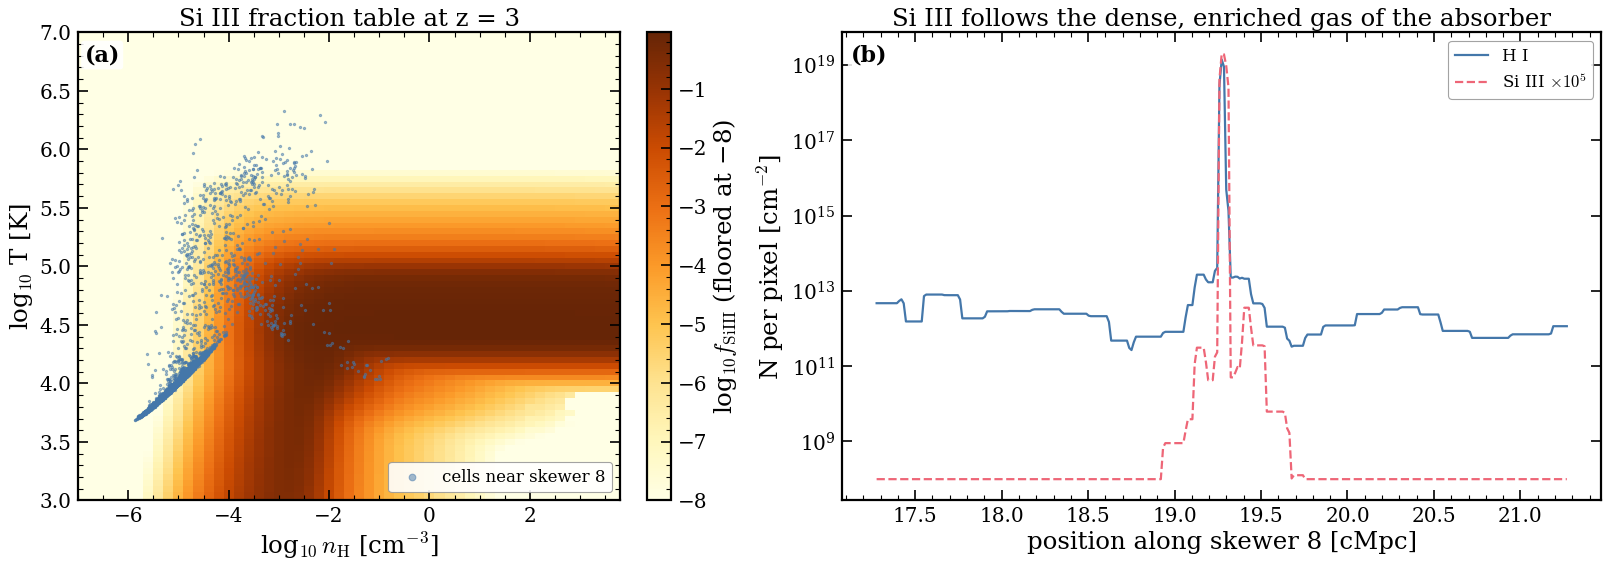

In [11]:
SI = gp.Ion("Si", 3)
sk8 = ss.SimulationSkewers.axis_aligned(rd, SETS["nset"]["cofm"][8:9], SETS["nset"]["axis"][8:9], DS_KMS, name="sk8", cache=CACHE)
Psi, Phi = sk8.properties(SI), sk8.properties(gp.HI)
cl = sk8._cloudy
print(f"sk8: {len(sk8.cells):,} cells | f_SiIII median {np.median(Psi['ion_fraction']):.2e}, X_Si median {np.median(np.asarray(sk8.cells.fields['metals'])[:, 7]):.2e}")
Nsi, Nhi = sk8.column_per_pixel(SI)[0], sk8.column_per_pixel(gp.HI)[0]
print(f"columns along skewer 8: log N_HI = {np.log10(Nhi.sum()):.2f}, log N_SiIII = {np.log10(Nsi.sum()):.2f}")
check("Si III column independent of the spacing (0.25 vs 4 km/s)",
      abs(dep.voronoi_segments(axis_aligned_skewer_points(SETS["nset"]["cofm"][8:9] * H.code_length_cMpc, SETS["nset"]["axis"][8:9], L, 4.0 / H.velfac_kms_per_cMpc),
                               sk8.cells.positions, L, gas_size=sk8.cells.size_cMpc).column_lengths(Psi["n_ion"]).sum() /
          sk8.segments("voronoi").column_lengths(Psi["n_ion"]).sum() - 1), 2e-5, "7")
fig, axs = plt.subplots(1, 2, figsize=(20, 7), layout="constrained", gridspec_kw={"width_ratios": [1, 1.4]})
grid = cl.log_fraction_grid(SI)
im = axs[0].pcolormesh(cl.log_dens, cl.log_temp, np.maximum(grid.T, -8), cmap=tol_cmap("YlOrBr"), shading="auto")
axs[0].scatter(np.log10(Psi["n_H"]), np.log10(Psi["T"]), s=4, c=EC["HI"], alpha=0.5, label="cells near skewer 8")
axs[0].set(xlabel=r"log$_{10}\,n_{\rm H}$ [cm$^{-3}$]", ylabel="log$_{10}$ T [K]", title="Si III fraction table at z = 3", xlim=(-7, 3.8), ylim=(3, 7))
axs[0].legend(loc="lower right", markerscale=3); fig.colorbar(im, ax=axs[0], label=r"log$_{10} f_{\rm SiIII}$ (floored at −8)")
xpix = (np.arange(Nsi.size) + 0.5) * L / Nsi.size
j = np.argmax(Nhi); wv = np.abs(xpix - xpix[j]) < 2.0
axs[1].semilogy(xpix[wv], np.maximum(Nhi[wv], 1e8), color=EC["HI"], **MS["default"], label="H I")
axs[1].semilogy(xpix[wv], np.maximum(Nsi[wv] * 1e5, 1e8), color=EC["SiIII"], **MS["matched"], label=r"Si III $\times 10^5$")
axs[1].set(xlabel="position along skewer 8 [cMpc]", ylabel=r"N per pixel [cm$^{-2}$]", title="Si III follows the dense, enriched gas of the absorber")
axs[1].legend(loc="upper right")
add_panel_letters(axs)
plt.show()

*Figure — left:* the Si III fraction over the (n_H, T) grid, with the cells around skewer 8. Si III is the dominant silicon ion (f ≳ 0.3) in gas denser than n_H ≈ 10⁻³ cm⁻³ and cooler than ≈ 10^4.8 K. Below that density the background ionises it further, and above ~10⁵ K collisions do (f ≈ 2×10⁻⁴ at 2×10⁵ K). *Right:* the H I and Si III columns around the damped absorber; Si III follows the dense, enriched gas.

Nothing else changes: the same `SimulationSkewers` object provides the Si III absorbers (`absorbers(SI)`) and the inputs of the optical depth, with the Si III line taken from `LineBundle(["SiIII-1206"])`.

## 8. The same in the style of `3_fields.ipynb`: fields from the simulation box

The steps of the toy-model notebook `3_fields.ipynb`, with the same calls and figures, on the simulation:
1. define the ingredients: the cosmology, the lines, the fields wanted for each species, and `SkewerBundle`s;
2. throw the skewers through the box and sample the fields at the skewer points;
3. plot them as in `3_fields.ipynb`.

Only one call is new. The toy model builds `Fields` from analytic samplers; here `SimulationSkewers.from_bundle(simulation, skewer_bundle).fields(species)` builds the same `Fields`, with the same keys and the same `fields.sample(...)` / `fields.temperature(...)` interface, from the gas cells the skewers cross. Each sampler returns the **segment average** of its sampling point: §5–6 above.

In [12]:
# ------------------------------------------------------------------ ingredients
import matplotlib as mpl
from matplotlib.lines import Line2D
from skewerjax.cosmology.cosmology import Cosmology
import skewerjax.utils.aux as aux

simulation = sr.ArepoHDF5Reader(SNAP_BASE, SNAPNUM)                              # the snapshot (a layer-1 reader)
Hs = simulation.header
L_box = Hs.box_cMpc                                                              # UNITS: [Mpc] (comoving)
cosmology = Cosmology(H0=100 * Hs.h * 1e6 * phys.Gyr_to_s / phys.Gpc_to_m,      # the simulation's own cosmology
                      Omega_r_0=0.0, Omega_m_0=Hs.omega_m, Omega_k_0=0.0, Omega_lambda_0=Hs.omega_l)
line_bundle = LineBundle(["HI-LyA", "SiIII-1206"], ref_line_id="HI-LyA")
species = line_bundle.species_keys                                               # the species whose fields we want
FIELD_NAMES = ("temperature", "velocity", "number_density", "turbulence", "collisional")
print(f"box {L_box:.3f} cMpc at z = {Hs.redshift:.3f} | lines {[l.id for l in line_bundle.lines]} | species {species} | fields {FIELD_NAMES}")

box 51.668 cMpc at z = 3.008 | lines ['HI-LyA', 'SiIII-1206'] | species ['HI', 'SiIII'] | fields ('temperature', 'velocity', 'number_density', 'turbulence', 'collisional')


In [13]:
# ------------------------------------------------------------------ SkewerBundles (as in 3_fields.ipynb)
N_sk = 7
N_ppsk = 17
N_grid = 48
bundle_kw = dict(a0=Hs.a, ICs_defined_at_index=0, ICs_at_emission_or_absorption="absorption", cosmologies=cosmology)   # observer before the first point

_points_1 = aux.make_plane_points(L_box, 'y', L_box / 2, N_sk, N_ppsk)            # skewers along x, in the plane y = L/2
skewer_bundle_1 = SkewerBundle(spatial_points=_points_1, **bundle_kw)
_points_T_imshow = aux.make_plane_points(L_box, 'y', L_box / 2, N_grid, N_grid)
skewer_bundle_T_imshow = SkewerBundle(spatial_points=_points_T_imshow, **bundle_kw)
_points_2 = aux.make_plane_points(L_box, 'x', L_box / 2, N_sk, N_ppsk)            # skewers along z, in the plane x = L/2
skewer_bundle_2 = SkewerBundle(spatial_points=_points_2, **bundle_kw)
_points_n_imshow = aux.make_plane_points(L_box, 'x', L_box / 2, N_grid, N_grid)
skewer_bundle_n_imshow = SkewerBundle(spatial_points=_points_n_imshow, **bundle_kw)

In [14]:
# ------------------------------------------------------------------ throw the skewers through the box and sample the fields
ii_cosmology = 0
t = time.perf_counter()
fields_1 = ss.SimulationSkewers.from_bundle(simulation, skewer_bundle_1).fields(species)          # a Fields, as in 3_fields.ipynb
fields_T = ss.SimulationSkewers.from_bundle(simulation, skewer_bundle_T_imshow).fields(species)
fields_2 = ss.SimulationSkewers.from_bundle(simulation, skewer_bundle_2).fields(species)
fields_n = ss.SimulationSkewers.from_bundle(simulation, skewer_bundle_n_imshow).fields(species)
print(f"fields of the four bundles extracted in {time.perf_counter() - t:.0f} s")

quadri_vectors_1 = skewer_bundle_1.quadri_vectors[ii_cosmology]
LoS_directions_1 = skewer_bundle_1.los_directions
sampled_fields_1 = fields_1.sample(quadri_vectors_1, LoS_directions_1)

quadri_vectors_T_imshow = skewer_bundle_T_imshow.quadri_vectors[ii_cosmology]
T_imshow = fields_T.temperature(quadri_vectors_T_imshow)

quadri_vectors_2 = skewer_bundle_2.quadri_vectors[ii_cosmology]
LoS_directions_2 = skewer_bundle_2.los_directions
sampled_fields_2 = fields_2.sample(quadri_vectors_2, LoS_directions_2)

quadri_vectors_n_imshow = skewer_bundle_n_imshow.quadri_vectors[ii_cosmology]
n_imshow = fields_n.number_density(quadri_vectors_n_imshow)
print("sampled_fields_1:", {sp: sorted(d) for sp, d in sampled_fields_1.items()}, "| T_imshow", tuple(T_imshow.shape), "| n_imshow", tuple(n_imshow.shape))
check("sampled fields have the keys and shapes of the toy-model Fields", float(not (
      set(sampled_fields_1) == set(species) and all(np.shape(sampled_fields_1[sp]["temperature"]) == (N_sk, N_ppsk) and
      np.shape(sampled_fields_1[sp]["velocity"]) == (N_sk, N_ppsk, 3) for sp in species))), 0, "8")
sk1 = ss.SimulationSkewers.from_bundle(simulation, skewer_bundle_1)
pv = sk1.point_values(gp.HI)
check("segment averages x line elements = the deposited column of every skewer", np.abs(
      (np.asarray(sampled_fields_1["HI"]["number_density"]) / Hs.a ** 3 * sk1.line_elements).sum(-1) /
      sk1.segments("voronoi").column_lengths(sk1.properties(gp.HI)["n_ion"]).sum(-1) - 1).max(), 1e-10, "8")

fields of the four bundles extracted in 23 s
sampled_fields_1: {'HI': ['LoS_velocity', 'collisional', 'number_density', 'temperature', 'turbulence', 'velocity'], 'SiIII': ['LoS_velocity', 'collisional', 'number_density', 'temperature', 'turbulence', 'velocity']} | T_imshow (2, 48, 48) | n_imshow (2, 48, 48)
[PASS] 8     sampled fields have the keys and shapes of the toy-model Fields: 0.000e+00 (<= 0) 
[PASS] 8     segment averages x line elements = the deposited column of every skewer: 0.000e+00 (<= 1e-10) 


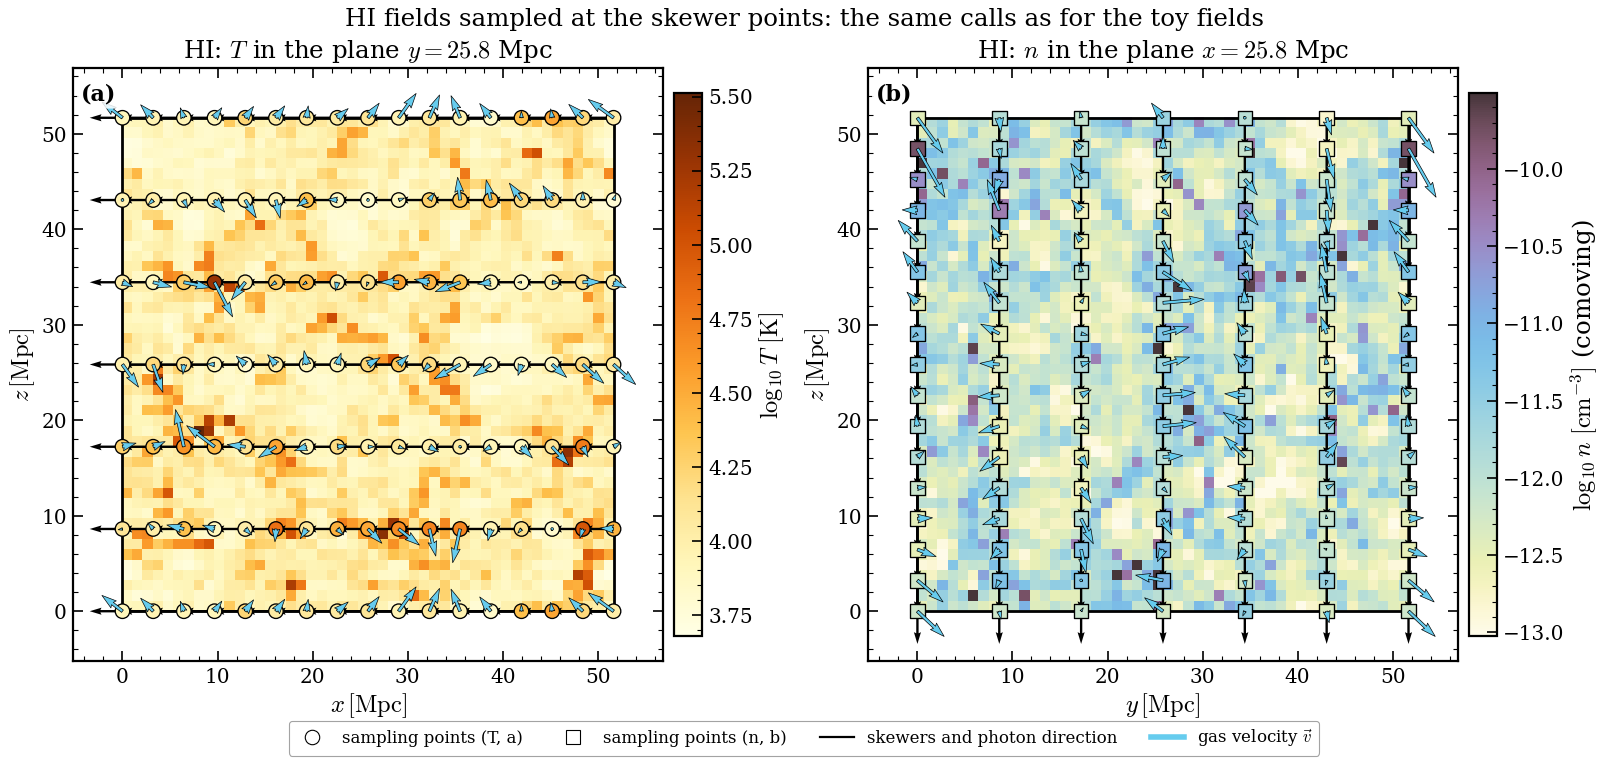

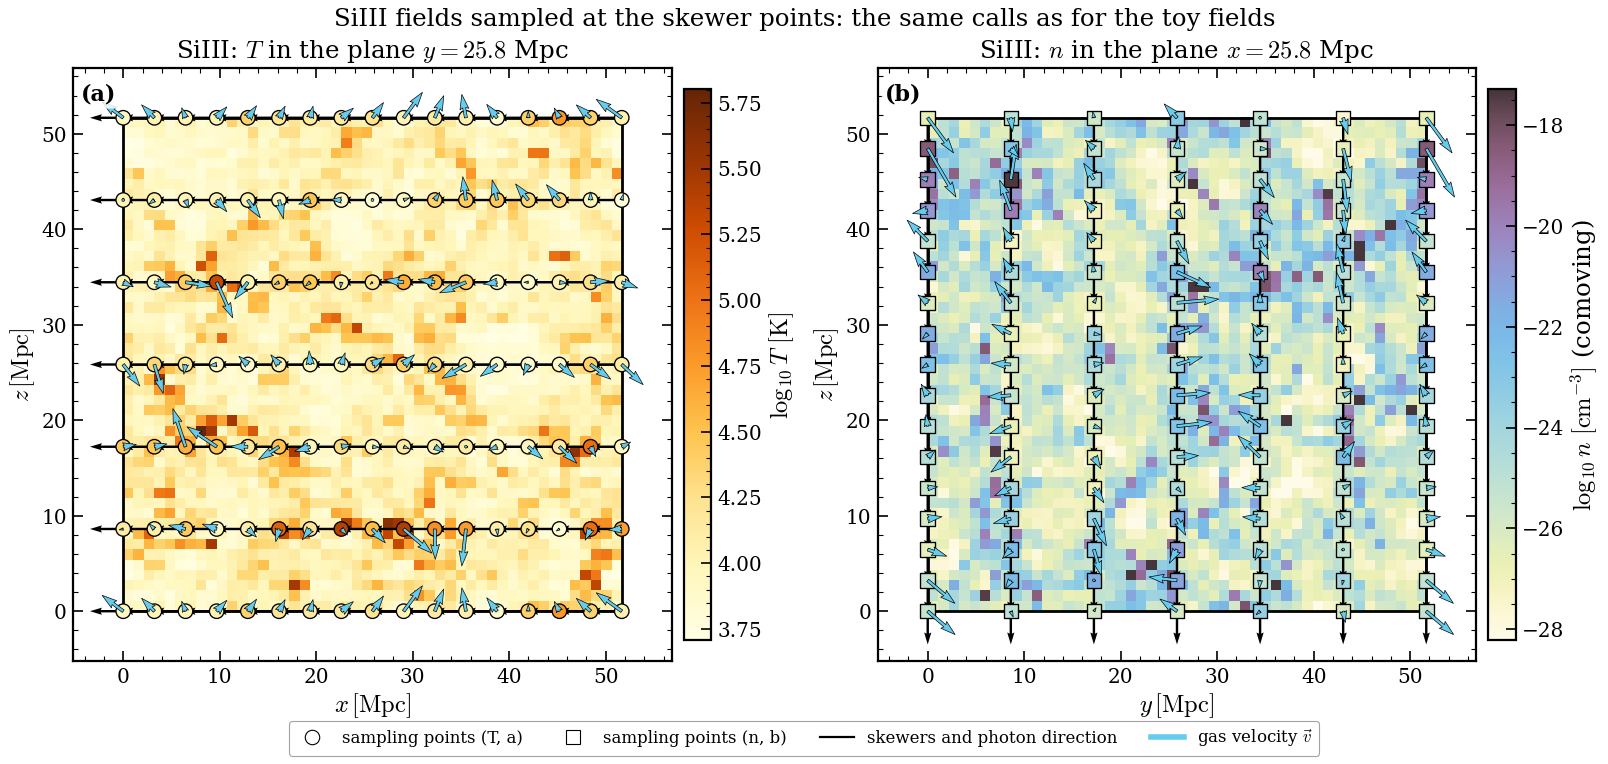

In [15]:
marker_scatter_1, marker_scatter_2 = "o", "s"
cmap_T, cmap_n = tol_cmap("YlOrBr"), tol_cmap("iridescent")
vel_kw = dict(color=EC["velocity"], edgecolor="k", linewidth=0.6, angles="xy", scale_units="xy", scale=60.0, width=0.005)   # 180 km/s -> 3 Mpc
for i_species, key_species in enumerate(species):
    fig, (axT, axN) = plt.subplots(1, 2, figsize=(20, 9.5), layout="constrained")
    # ---------------- (a) temperature slice (x-z, y = L_box/2)
    logT = np.log10(np.asarray(T_imshow[i_species]))
    x_min, x_max = float(quadri_vectors_T_imshow[..., 1].min()), float(quadri_vectors_T_imshow[..., 1].max())
    z_min_T, z_max_T = float(quadri_vectors_T_imshow[..., -1].min()), float(quadri_vectors_T_imshow[..., -1].max())
    norm_T = mpl.colors.Normalize(vmin=logT.min(), vmax=logT.max())
    im_T = axT.imshow(logT, origin="lower", extent=(x_min, x_max, z_min_T, z_max_T), aspect="auto", cmap=cmap_T, norm=norm_T)
    fig.colorbar(im_T, ax=axT, pad=0.02, fraction=0.046).set_label(r"$\log_{10} T\ \mathrm{[K]}$")
    T_all = np.asarray(sampled_fields_1[key_species]["temperature"])
    axT.scatter(np.asarray(quadri_vectors_1[..., 1]).ravel(), np.asarray(quadri_vectors_1[..., -1]).ravel(), c=np.log10(T_all).ravel(),
                cmap=cmap_T, norm=norm_T, marker=marker_scatter_1, s=170, edgecolor="k", linewidth=1.2, zorder=3)
    for i in range(quadri_vectors_1.shape[0]):
        axT.plot(quadri_vectors_1[i, ..., 1], quadri_vectors_1[i, ..., -1], color="k", linewidth=1.5, zorder=2)
        axT.quiver(quadri_vectors_1[i, ..., 1], quadri_vectors_1[i, ..., -1], LoS_directions_1[i, :, 0], LoS_directions_1[i, :, 2],
                   color="k", angles="xy", scale_units="xy", scale=None, width=0.004, zorder=2)
    axT.quiver(quadri_vectors_1[..., 1], quadri_vectors_1[..., -1], sampled_fields_1[key_species]["velocity"][..., 0],
               sampled_fields_1[key_species]["velocity"][..., 2], zorder=4, **vel_kw)
    axT.plot([x_min, x_max, x_max, x_min, x_min], [z_min_T, z_min_T, z_max_T, z_max_T, z_min_T], color="k", linewidth=2.5)
    pad = 0.1 * L_box
    axT.set_xlim(x_min - pad, x_max + pad); axT.set_ylim(z_min_T - pad, z_max_T + pad)
    axT.set_xlabel(r"$x\, [\mathrm{Mpc}]$"); axT.set_ylabel(r"$z\, [\mathrm{Mpc}]$")
    axT.set_title(rf"{key_species}: $T$ in the plane $y={L_box / 2:.3g}$ Mpc", pad=10)
    # ---------------- (b) number-density slice (y-z, x = L_box/2)
    logn = np.log10(np.asarray(n_imshow[i_species]))
    y_min, y_max = float(quadri_vectors_n_imshow[..., 2].min()), float(quadri_vectors_n_imshow[..., 2].max())
    z_min_n, z_max_n = float(quadri_vectors_n_imshow[..., 3].min()), float(quadri_vectors_n_imshow[..., 3].max())
    norm_n = mpl.colors.Normalize(vmin=np.percentile(logn, 1), vmax=np.percentile(logn, 99.5))
    im_n = axN.imshow(logn.T, origin="lower", extent=(y_min, y_max, z_min_n, z_max_n), aspect="auto", cmap=cmap_n, norm=norm_n)
    fig.colorbar(im_n, ax=axN, pad=0.02, fraction=0.046).set_label(r"$\log_{10} n\ \mathrm{[cm^{-3}]}$ (comoving)")
    n_all = np.asarray(sampled_fields_2[key_species]["number_density"])
    axN.scatter(np.asarray(quadri_vectors_2[..., 2]).ravel(), np.asarray(quadri_vectors_2[..., 3]).ravel(), c=np.log10(n_all).ravel(),
                cmap=cmap_n, norm=norm_n, marker=marker_scatter_2, s=170, edgecolor="k", linewidth=1.2, zorder=3)
    for i in range(quadri_vectors_2.shape[0]):
        axN.plot(quadri_vectors_2[i, ..., 2], quadri_vectors_2[i, ..., 3], color="k", linewidth=1.5, zorder=2)
        axN.quiver(quadri_vectors_2[i, ..., 2], quadri_vectors_2[i, ..., 3], LoS_directions_2[i, :, 1], LoS_directions_2[i, :, 2],
                   color="k", angles="xy", scale_units="xy", scale=None, width=0.004, zorder=2)
    axN.quiver(quadri_vectors_2[..., 2], quadri_vectors_2[..., 3], sampled_fields_2[key_species]["velocity"][..., 1],
               sampled_fields_2[key_species]["velocity"][..., 2], zorder=4, **vel_kw)
    axN.plot([y_min, y_max, y_max, y_min, y_min], [z_min_n, z_min_n, z_max_n, z_max_n, z_min_n], color="k", linewidth=2.5)
    axN.set_xlim(y_min - pad, y_max + pad); axN.set_ylim(z_min_n - pad, z_max_n + pad)
    axN.set_xlabel(r"$y\, [\mathrm{Mpc}]$"); axN.set_ylabel(r"$z\, [\mathrm{Mpc}]$")
    axN.set_title(rf"{key_species}: $n$ in the plane $x={L_box / 2:.3g}$ Mpc", pad=10)
    handles = [Line2D([0], [0], marker="o", linestyle="none", markerfacecolor="w", markeredgecolor="k", markersize=13, label="sampling points (T, a)"),
               Line2D([0], [0], marker="s", linestyle="none", markerfacecolor="w", markeredgecolor="k", markersize=13, label="sampling points (n, b)"),
               Line2D([0], [0], color="k", lw=2, label="skewers and photon direction"), Line2D([0], [0], color=EC["velocity"], lw=5, label=r"gas velocity $\vec{v}$")]
    fig.legend(handles=handles, loc="outside lower center", ncols=4, frameon=True)
    fig.suptitle(f"{key_species} fields sampled at the skewer points: the same calls as for the toy fields", fontsize=22)
    add_panel_letters([axT, axN])
    plt.show()

*Figures — one per species, as in `3_fields.ipynb`.*
- **Backgrounds:** the temperature in the plane y = L/2 (left) and the number density in the plane x = L/2 (right), each from a 48 × 48 bundle.
- **Markers:** the 7 skewers of 17 points, coloured with the same scale. Black arrows show the photon direction, cyan arrows the gas velocity.

Unlike the toy fields, the simulation's fields vary along every skewer. Each marker, and each background pixel, is the average over its dual segment along its own skewer: 3.2 cMpc for the markers and 1.1 cMpc for the backgrounds. The backgrounds are therefore smoothed along x on the left and along z on the right, hence the streaks. With fine sampling the same call gives the cell-by-cell fields of §5.

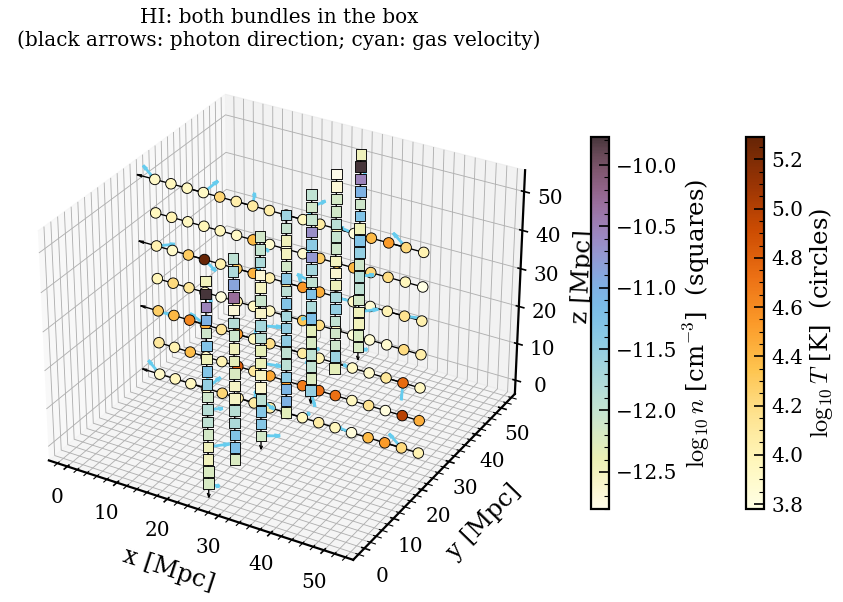

In [16]:
# ------------------------------------------------------------------ 3D view (as in 3_fields.ipynb), H I
key_species = "HI"
fig = plt.figure(figsize=(14, 11)); ax = fig.add_subplot(111, projection="3d")
qv1, qv2 = np.asarray(quadri_vectors_1), np.asarray(quadri_vectors_2)
logT_y = np.log10(np.asarray(sampled_fields_1[key_species]["temperature"])); logn_x = np.log10(np.asarray(sampled_fields_2[key_species]["number_density"]))
norm_T, norm_n = mpl.colors.Normalize(logT_y.min(), logT_y.max()), mpl.colors.Normalize(logn_x.min(), logn_x.max())
cmT, cmN = tol_cmap("YlOrBr"), tol_cmap("iridescent")
for qv, val, norm, cmap, mk, vel, los in ((qv1, logT_y, norm_T, cmT, "o", sampled_fields_1[key_species]["velocity"], LoS_directions_1),
                                          (qv2, logn_x, norm_n, cmN, "s", sampled_fields_2[key_species]["velocity"], LoS_directions_2)):
    ax.scatter(qv[..., 1].ravel(), qv[..., 2].ravel(), qv[..., 3].ravel(), c=cmap(norm(val.ravel())), marker=mk, s=90, edgecolor="k", linewidth=0.8, depthshade=False)
    for i in range(qv.shape[0]):
        ax.plot(qv[i, :, 1], qv[i, :, 2], qv[i, :, 3], color="k", linewidth=1.2)
    st = (slice(None, None, 2), slice(None, None, 3))
    vel, los = np.asarray(vel), np.asarray(los)
    ax.quiver(qv[st][..., 1], qv[st][..., 2], qv[st][..., 3], los[st][..., 0], los[st][..., 1], los[st][..., 2], length=0.07 * L_box, normalize=True, color="k", linewidth=1.2)
    ax.quiver(qv[st][..., 1], qv[st][..., 2], qv[st][..., 3], vel[st][..., 0], vel[st][..., 1], vel[st][..., 2], length=0.07 * L_box, normalize=True, color=EC["velocity"], linewidth=2.5)
z_line = np.linspace(0.0, L_box, 100)
ax.plot(np.full_like(z_line, L_box / 2), np.full_like(z_line, L_box / 2), z_line, color="k", linewidth=2, alpha=0.5, ls="--")
for norm, cmap, lab in ((norm_T, cmT, r"$\log_{10} T$ [K]  (circles)"), (norm_n, cmN, r"$\log_{10} n$ [cm$^{-3}$]  (squares)")):
    fig.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, shrink=0.55, pad=0.06, label=lab)
ax.set_xlabel("x [Mpc]", labelpad=18); ax.set_ylabel("y [Mpc]", labelpad=18); ax.set_zlabel("z [Mpc]", labelpad=14)
ax.set_title(f"{key_species}: both bundles in the box\n(black arrows: photon direction; cyan: gas velocity)", fontsize=18)
plt.show()

*Figure — the two bundles in 3D*, as in `3_fields.ipynb`: the plane y = L/2 (circles, coloured by T) and the plane x = L/2 (squares, coloured by n), with the photon directions (black) and the gas velocities (cyan).

**Summary.**
- *Toy model:* `fields = Fields({...analytic samplers...})`.
- *Simulation:* `fields = SimulationSkewers.from_bundle(simulation, skewer_bundle).fields(species)`.

Everything after that line is identical.

## 9. Summary of the checks

In [17]:
import collections, resource
print(f"{'tag':12s} {'section':7s} name")
for r in RESULTS:
    print(f"{r['tag']:12s} {r['section']:7s} {r['name']}  ({r['value']:.2e} {'>' if r['kind'] == 'expect' else '<='} {r['tol']:g}) {r['detail']}")
print("\nSUMMARY:", dict(collections.Counter(r["tag"] for r in RESULTS)), f"of {len(RESULTS)} checks")
print(f"wall time {time.perf_counter() - T_START:.0f} s | peak memory {resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1e6:.1f} GB")

tag          section name
PASS         3       stored x_HI == ionisation equilibrium (diffuse gas, n_H < 1e-4 cm^-3): median |ratio - 1|  (9.29e-04 <= 0.002) (41,291 cells)
PASS         3       default x_HI = stored outside star-forming cells  (0.00e+00 <= 0) 
PASS         4       line elements of a skewer sum to the box length  (0.00e+00 <= 1e-12) 
PASS         4       selection complete (single): the nearest generating point over all 19,250,411 cells is selected  (0.00e+00 <= 0) (31,694 probes)
PASS         4       selection complete (nset): the nearest generating point over all 19,250,411 cells is selected  (0.00e+00 <= 0) (507,104 probes)
PASS         5       the pieces fill every dual segment exactly (single)  (2.18e-12 <= 1e-09) 
PASS         5       the pieces fill every dual segment exactly (nset)  (2.18e-12 <= 1e-09) 
PASS         5       the column is independent of the spacing of the points (0.25-64 km/s, 16 skewers)  (9.40e-06 <= 2e-05) 
PASS         5       column per pixe